<a href="https://colab.research.google.com/github/regional-specter/Vehicle-Inspection-Vision-Model/blob/main/structural-edge-boundary-analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Layer 1: Structural Edge & Boundary Analysis (Macro Damages)**
- Target Flaws: Severe tears, puncturing holes, deep gouges, and major body panel misalignment or detachment.
- Function: It looks for sharp, unexpected discontinuities in the outer perimeter or surface lines of doors, bumpers, and fenders. By enforcing geometric symmetry constraints (comparing the left side of the vehicle to the right or to a CAD template baseline), it instantly flags missing pieces or severe structural fractures.


**Step 1: Semantic Segmentation & Panel Isolation**
- Train or fine-tune a Mask R-CNN or YOLO-seg model on a custom vehicle dataset to parse individual body panels and extract pixel-precise masks.
- Apply homography or spatial transformer networks to warp each segmented panel into a canonical, flat reference coordinate system.


**Step 2: Contour & Edge Feature Extraction**
- Run adaptive Canny edge detection or learned contour-extraction networks (e.g., DexiNed) on the normalized panel crops to isolate primary structural boundaries and panel gaps.
- Compute the distance between the detected panel contours and a pre-stored CAD or pristine reference mask.


**Step 3: Symmetry Verification & Anomaly Scoring**
- Implement left-right mirror-symmetry checks across paired vehicle panels to calculate structural Hausdorff distances.
- Train a lightweight classification head (or threshold-based rules) on contour displacement vectors to flag macro anomalies like punctures, missing trim, or severe misalignments.


In [2]:
# Install YOLO and Kaggle client
!pip install ultralytics kaggle -q

import os
from pathlib import Path

# Download the dataset directly from Kaggle
!kaggle datasets download -d humansintheloop/car-parts-and-car-damages --unzip -p /content/dataset

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 10.3 MB/s eta 0:00:00
Dataset URL: https://www.kaggle.com/datasets/humansintheloop/car-parts-and-car-damages
License(s): CC0-1.0
100% 2.89G/2.89G [00:30<00:00, 101MB/s]



In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

from ultralytics import YOLO
import os
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
kagglehub.dataset_download('humansintheloop/car-parts-and-car-damages')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
/kaggle/input


100%|██████████| 2.89G/2.89G [00:27<00:00, 112MB/s]

Extracting files...


'/root/.cache/kagglehub/datasets/humansintheloop/car-parts-and-car-damages/versions/2'

In [4]:
import json
import cv2
import shutil
from sklearn.model_selection import train_test_split

# Updated paths for Google Colab
DATA_DIR = Path("/content/dataset/Car damages dataset/File1")
IMG_DIR = DATA_DIR / "img"
ANN_DIR = DATA_DIR / "ann"

OUTPUT_DIR = Path("/content/yolo_dataset")
for split in ["train", "val"]:
    (OUTPUT_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

# 3. Dynamic class mapping: Collect unique classes found in the dataset automatically
print("Scanning dataset to build class list...")
unique_classes = set()
for json_path in ANN_DIR.glob("*.json"):
    with open(json_path, 'r') as f:
        data = json.load(f)
        for obj in data.get('objects', []):
            if 'classTitle' in obj:
                unique_classes.add(obj['classTitle'])

classes = sorted(list(unique_classes))
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
print(f"Discovered classes ({len(classes)}): {classes}")

# 4. Train/Val Split (80% train, 20% validation)
image_files = list(IMG_DIR.glob("*.*"))
train_imgs, val_imgs = train_test_split(image_files, test_size=0.2, random_state=42)

def process_split(files, split_name):
    success_count = 0
    for img_path in files:
        img_name = img_path.name
        json_path = ANN_DIR / f"{img_name}.json"

        if not json_path.exists():
            continue

        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w, _ = img.shape

        # Copy image to YOLO split directory
        shutil.copy(img_path, OUTPUT_DIR / "images" / split_name / img_name)

        with open(json_path, 'r') as f:
            data = json.load(f)

        txt_lines = []
        for obj in data.get('objects', []):
            label = obj.get('classTitle')
            if label not in class_to_idx:
                continue
            class_id = class_to_idx[label]

            # Extract points from points['exterior'] structure
            points_dict = obj.get('points', {})
            exterior_pts = points_dict.get('exterior', [])

            normalized_pts = []
            for pt in exterior_pts:
                # pt is formatted as [x, y]
                if isinstance(pt, list) and len(pt) >= 2:
                    px = pt[0] / w
                    py = pt[1] / h
                    normalized_pts.extend([round(px, 6), round(py, 6)])

            if len(normalized_pts) >= 6:  # Valid polygon needs at least 3 points
                line = f"{class_id} " + " ".join(map(str, normalized_pts))
                txt_lines.append(line)

        # Save corresponding .txt label file
        txt_path = OUTPUT_DIR / "labels" / split_name / f"{img_path.stem}.txt"
        with open(txt_path, 'w') as tf:
            tf.write("\n".join(txt_lines))

        if len(txt_lines) > 0:
            success_count += 1

    print(f"Processed {split_name}: {success_count} valid label files created.")

process_split(train_imgs, "train")
process_split(val_imgs, "val")
print("Dataset conversion re-run completed successfully!")

Scanning dataset to build class list...
Discovered classes (21): ['Back-bumper', 'Back-door', 'Back-wheel', 'Back-window', 'Back-windshield', 'Fender', 'Front-bumper', 'Front-door', 'Front-wheel', 'Front-window', 'Grille', 'Headlight', 'Hood', 'License-plate', 'Mirror', 'Quarter-panel', 'Rocker-panel', 'Roof', 'Tail-light', 'Trunk', 'Windshield']
Processed train: 798 valid label files created.
Processed val: 200 valid label files created.
Dataset conversion re-run completed successfully!


In [5]:
# Create YAML file with dynamically mapped classes
formatted_names = "\n".join([f"  {i}: {name}" for i, name in enumerate(classes)])

yaml_content = f"""
path: {OUTPUT_DIR.resolve()}
train: images/train
val: images/val

names:
{formatted_names}
"""

yaml_file_path = OUTPUT_DIR / "car_parts.yaml"
with open(yaml_file_path, "w") as f:
    f.write(yaml_content.strip())

print(f"Updated YAML config created at: {yaml_file_path}")

Updated YAML config created at: /content/yolo_dataset/car_parts.yaml


In [6]:
from pathlib import Path

label_dir = Path("/kaggle/working/yolo_dataset/labels/train")
sample_txt = next(label_dir.glob("*.txt"))

print(f"Checking file: {sample_txt.name}")
print("Content:", repr(sample_txt.read_text()))

StopIteration: 

In [ ]:
import json
from pathlib import Path

ann_dir = Path("/kaggle/input/datasets/humansintheloop/car-parts-and-car-damages/Car damages dataset/File1/ann")
sample_json = next(ann_dir.glob("*.json"))

with open(sample_json, 'r') as f:
    data = json.load(f)

print(json.dumps(data, indent=2)[:1000])  # Prints first 1000 characters of the JSON structure

In [7]:
from ultralytics import YOLO

model = YOLO("yolov8n-seg.pt")

results = model.train(
    data=str(yaml_file_path),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0  # Uses the Google Colab T4 GPU
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/car_parts.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=Fa


WARNING ⚠️ imgsz=[1080] must be multiple of max stride 32, updating to [1088]
image 1/1 /test_image.jpg: 1056x1088 1 Back-bumper, 1 Rocker-panel, 43.6ms
Speed: 8.8ms preprocess, 43.6ms inference, 3.5ms postprocess per image at shape (1, 3, 1056, 1088)


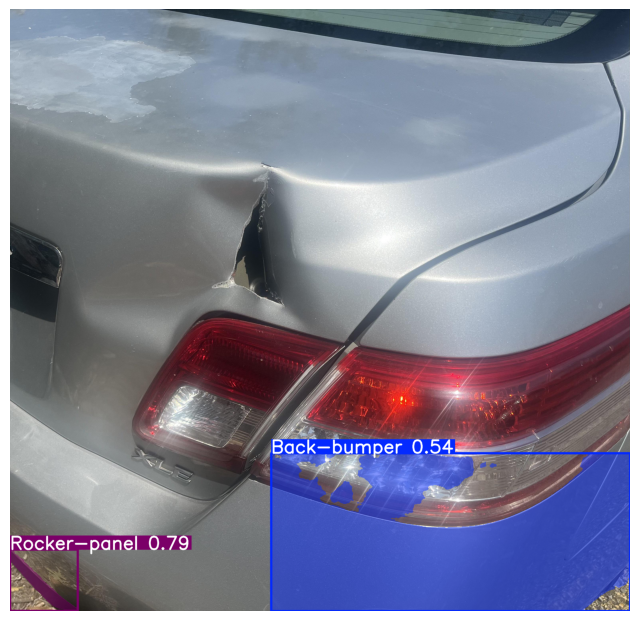

In [10]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# 1. Load your newly trained custom segmentation model weights
model = YOLO("/content/runs/segment/train/weights/best.pt")

# 2. Run inference on a test image (replace with your own image path)
test_image_path = "/test_image.jpg" # Or any sample path
results = model(test_image_path, imgsz=1080, conf=0.4)

# 3. Plot and display the segmented results inline in Colab
res_plotted = results[0].plot()  # Draws bounding boxes, labels, and pixel-precise masks
res_rgb = cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(res_rgb)
plt.axis('off')
plt.show()